In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.interpolate import RBFInterpolator
from scipy.spatial import cKDTree
#%matplotlib widget

z-score crop: dropped 5 of 405 cases (|z| > 5)
              folder    tp   dx    q_tot          z
run_tp_14.65_dx_5.43 14.65 5.43 0.000000 -16.365384
run_tp_06.67_dx_5.90  6.67 5.90 0.000000 -16.200601
run_tp_08.48_dx_3.60  8.48 3.60 0.050904   6.374537
run_tp_11.50_dx_5.34 11.50 5.34 0.078428   5.996059
run_tp_14.99_dx_4.85 14.99 4.85 0.113604   5.327563
cross-validated RMS error by smoothing: {0.0: '0.00544', 0.001: '0.00462', 0.01: '0.00383', 0.1: '0.00367', 1.0: '0.0037', 10.0: '0.00373'} -> using 0.1


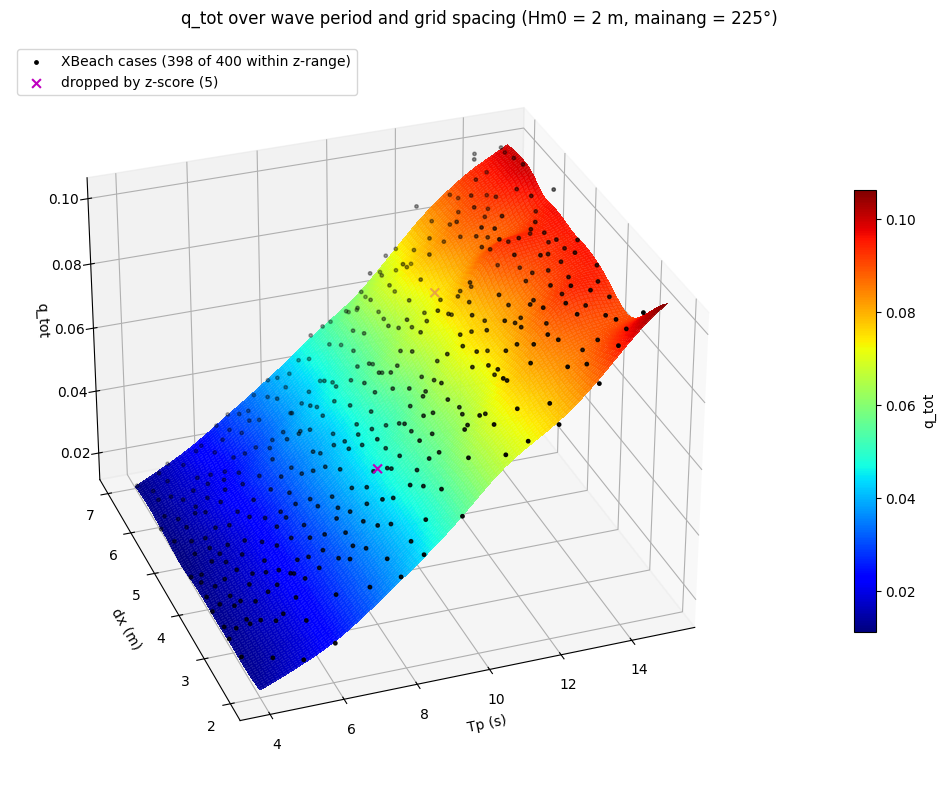

In [4]:
n = 100              # surface grid resolution
smoothing = None       # RBF smoothing: None = choose by cross-validation; 0 = pass exactly through every case
show_data = True     # overlay the XBeach cases as black dots
custom_axes = False
z_crop = True        # drop cases that disagree with their neighbours before fitting the surface
Z_MAX = 5.0          # robust z-score threshold (lower = stricter)
K = 15               # neighbours used to judge each case

df = pd.read_csv("q_tot_summary_sensitivity_surfbeat.csv")
pts = df[["tp", "dx"]].to_numpy()
q = df["q_tot"].to_numpy()

# ---- crop by local z-score: compare each case with a linear fit through its K nearest neighbours.
# (A global z-score would flag the long-period cases, which are large because of Tp, not errors.)
dropped = df.iloc[0:0]
if z_crop:
    Xn = (pts - pts.mean(axis=0)) / pts.std(axis=0)
    nbrs = cKDTree(Xn).query(Xn, k=K + 1)[1][:, 1:]          # neighbours, excluding the case itself
    floor = 0.01 * np.percentile(np.abs(q), 99)               # ignore deviations that are tiny overall
    keep = np.ones(len(q), bool)
    for _ in range(2):                                        # 2nd pass: judge against cleaned neighbours
        z = np.zeros(len(q))
        for i in range(len(q)):
            nb = nbrs[i][keep[nbrs[i]]]
            A = np.column_stack([np.ones(len(nb)), Xn[nb] - Xn[i]])
            coef = np.linalg.lstsq(A, q[nb], rcond=None)[0]
            res = q[nb] - A @ coef
            scale = max(1.4826 * np.median(np.abs(res - np.median(res))), floor)
            z[i] = (q[i] - coef[0]) / scale
        keep = np.abs(z) <= Z_MAX
    dropped = df.loc[~keep].assign(z=z[~keep]).sort_values("z", key=np.abs, ascending=False)
    print(f"z-score crop: dropped {len(dropped)} of {len(df)} cases (|z| > {Z_MAX:g})")
    if len(dropped):
        print(dropped[["folder", "tp", "dx", "q_tot", "z"]].to_string(index=False))
    df, pts, q = df.loc[keep].reset_index(drop=True), pts[keep], q[keep]

# RBF surface over Tp and dx (inputs scaled so both axes count equally)
p_mean, p_std = pts.mean(axis=0), pts.std(axis=0)
Xs = (pts - p_mean) / p_std
if smoothing is None:                              # 5-fold cross-validation: best prediction of held-out cases
    fold = np.random.default_rng(0).integers(0, 5, len(q))
    cv = {sm: np.sqrt(np.mean([np.mean((RBFInterpolator(Xs[fold != k], q[fold != k], kernel="cubic", smoothing=sm)
                                        (Xs[fold == k]) - q[fold == k]) ** 2) for k in range(5)]))
          for sm in (0.0, 1e-3, 1e-2, 1e-1, 1.0, 10.0)}
    smoothing = min(cv, key=cv.get)
    print("cross-validated RMS error by smoothing:", {k: f"{v:.3g}" for k, v in cv.items()}, "-> using", smoothing)
rbf = RBFInterpolator(Xs, q, kernel="cubic", smoothing=smoothing)
tp_g, dx_g = np.meshgrid(np.linspace(df["tp"].min(), df["tp"].max(), n),
                         np.linspace(df["dx"].min(), df["dx"].max(), n))
q_g = rbf((np.column_stack([tp_g.ravel(), dx_g.ravel()]) - p_mean) / p_std).reshape(tp_g.shape)

zlim = (-0.1, 0.1) if custom_axes else (q_g.min(), q_g.max())
cmap = plt.get_cmap("jet")
if zlim[0] < 0 < zlim[1]:                          # both directions shown: centre the colours on 0
    norm = mcolors.TwoSlopeNorm(vmin=zlim[0], vcenter=0, vmax=zlim[1])
else:
    norm = mcolors.Normalize(*zlim)

# 3D axes don't clip to their limits, so hide what's outside the z-range before plotting
q_plot = np.where((q_g >= zlim[0]) & (q_g <= zlim[1]), q_g, np.nan)
inside = df["q_tot"].between(*zlim)
drop_in = dropped["q_tot"].between(*zlim)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.computed_zorder = False                         # keep the data dots drawn on top of the surface
ax.plot_surface(tp_g, dx_g, q_plot, facecolors=cmap(norm(q_plot)), rstride=1, cstride=1,
                shade=False, linewidth=0, antialiased=False, alpha=0.9)
if show_data:
    ax.scatter(df.loc[inside, "tp"], df.loc[inside, "dx"], df.loc[inside, "q_tot"], c="k", s=6,
               label=f"XBeach cases ({inside.sum()} of {len(df)} within z-range)")
    if drop_in.any():
        ax.scatter(dropped.loc[drop_in, "tp"], dropped.loc[drop_in, "dx"], dropped.loc[drop_in, "q_tot"],
                   c="m", marker="x", s=40, label=f"dropped by z-score ({len(dropped)})")
    ax.legend(loc="upper left")
ax.set_xlabel("Tp (s)")
ax.set_ylabel("dx (m)")
ax.set_zlabel("q_tot")
ax.set_zlim(zlim)
ax.grid(True, linestyle=":", alpha=0.5)
ax.view_init(elev=30, azim=250, roll=0)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="q_tot")
plt.suptitle("q_tot over wave period and grid spacing (Hm0 = 2 m, mainang = 225°)")
plt.tight_layout()
plt.show()

z-score crop: dropped 2 of 500 cases (|z| > 5)
              folder    tp   dx     q_tot         z
run_tp_11.72_dx_3.18 11.72 3.18 -0.361267 -7.454493
run_tp_10.07_dx_2.01 10.07 2.01 -0.456435 -5.738019
cross-validated RMS error by smoothing: {0.0: '0.0926', 0.001: '0.0873', 0.01: '0.0769', 0.1: '0.0729', 1.0: '0.083', 10.0: '0.0927'} -> using 0.1


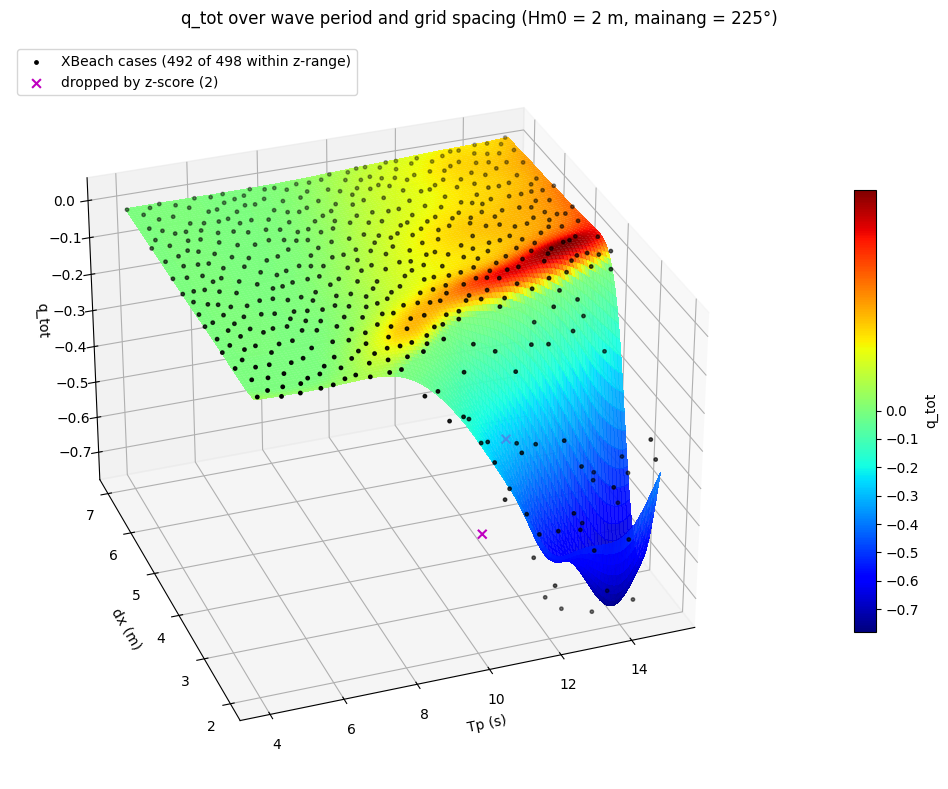

In [5]:
n = 100              # surface grid resolution
smoothing = None       # RBF smoothing: None = choose by cross-validation; 0 = pass exactly through every case
show_data = True     # overlay the XBeach cases as black dots
custom_axes = False
z_crop = True        # drop cases that disagree with their neighbours before fitting the surface
Z_MAX = 5.0          # robust z-score threshold (lower = stricter)
K = 15               # neighbours used to judge each case

df = pd.read_csv("q_tot_summary_sensitivity_nonh.csv")
pts = df[["tp", "dx"]].to_numpy()
q = df["q_tot"].to_numpy()

# ---- crop by local z-score: compare each case with a linear fit through its K nearest neighbours.
# (A global z-score would flag the long-period cases, which are large because of Tp, not errors.)
dropped = df.iloc[0:0]
if z_crop:
    Xn = (pts - pts.mean(axis=0)) / pts.std(axis=0)
    nbrs = cKDTree(Xn).query(Xn, k=K + 1)[1][:, 1:]          # neighbours, excluding the case itself
    floor = 0.01 * np.percentile(np.abs(q), 99)               # ignore deviations that are tiny overall
    keep = np.ones(len(q), bool)
    for _ in range(2):                                        # 2nd pass: judge against cleaned neighbours
        z = np.zeros(len(q))
        for i in range(len(q)):
            nb = nbrs[i][keep[nbrs[i]]]
            A = np.column_stack([np.ones(len(nb)), Xn[nb] - Xn[i]])
            coef = np.linalg.lstsq(A, q[nb], rcond=None)[0]
            res = q[nb] - A @ coef
            scale = max(1.4826 * np.median(np.abs(res - np.median(res))), floor)
            z[i] = (q[i] - coef[0]) / scale
        keep = np.abs(z) <= Z_MAX
    dropped = df.loc[~keep].assign(z=z[~keep]).sort_values("z", key=np.abs, ascending=False)
    print(f"z-score crop: dropped {len(dropped)} of {len(df)} cases (|z| > {Z_MAX:g})")
    if len(dropped):
        print(dropped[["folder", "tp", "dx", "q_tot", "z"]].to_string(index=False))
    df, pts, q = df.loc[keep].reset_index(drop=True), pts[keep], q[keep]

# RBF surface over Tp and dx (inputs scaled so both axes count equally)
p_mean, p_std = pts.mean(axis=0), pts.std(axis=0)
Xs = (pts - p_mean) / p_std
if smoothing is None:                              # 5-fold cross-validation: best prediction of held-out cases
    fold = np.random.default_rng(0).integers(0, 5, len(q))
    cv = {sm: np.sqrt(np.mean([np.mean((RBFInterpolator(Xs[fold != k], q[fold != k], kernel="cubic", smoothing=sm)
                                        (Xs[fold == k]) - q[fold == k]) ** 2) for k in range(5)]))
          for sm in (0.0, 1e-3, 1e-2, 1e-1, 1.0, 10.0)}
    smoothing = min(cv, key=cv.get)
    print("cross-validated RMS error by smoothing:", {k: f"{v:.3g}" for k, v in cv.items()}, "-> using", smoothing)
rbf = RBFInterpolator(Xs, q, kernel="cubic", smoothing=smoothing)
tp_g, dx_g = np.meshgrid(np.linspace(df["tp"].min(), df["tp"].max(), n),
                         np.linspace(df["dx"].min(), df["dx"].max(), n))
q_g = rbf((np.column_stack([tp_g.ravel(), dx_g.ravel()]) - p_mean) / p_std).reshape(tp_g.shape)

zlim = (-0.1, 0.1) if custom_axes else (q_g.min(), q_g.max())
cmap = plt.get_cmap("jet")
if zlim[0] < 0 < zlim[1]:                          # both directions shown: centre the colours on 0
    norm = mcolors.TwoSlopeNorm(vmin=zlim[0], vcenter=0, vmax=zlim[1])
else:
    norm = mcolors.Normalize(*zlim)

# 3D axes don't clip to their limits, so hide what's outside the z-range before plotting
q_plot = np.where((q_g >= zlim[0]) & (q_g <= zlim[1]), q_g, np.nan)
inside = df["q_tot"].between(*zlim)
drop_in = dropped["q_tot"].between(*zlim)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.computed_zorder = False                         # keep the data dots drawn on top of the surface
ax.plot_surface(tp_g, dx_g, q_plot, facecolors=cmap(norm(q_plot)), rstride=1, cstride=1,
                shade=False, linewidth=0, antialiased=False, alpha=0.9)
if show_data:
    ax.scatter(df.loc[inside, "tp"], df.loc[inside, "dx"], df.loc[inside, "q_tot"], c="k", s=6,
               label=f"XBeach cases ({inside.sum()} of {len(df)} within z-range)")
    if drop_in.any():
        ax.scatter(dropped.loc[drop_in, "tp"], dropped.loc[drop_in, "dx"], dropped.loc[drop_in, "q_tot"],
                   c="m", marker="x", s=40, label=f"dropped by z-score ({len(dropped)})")
    ax.legend(loc="upper left")
ax.set_xlabel("Tp (s)")
ax.set_ylabel("dx (m)")
ax.set_zlabel("q_tot")
ax.set_zlim(zlim)
ax.grid(True, linestyle=":", alpha=0.5)
ax.view_init(elev=30, azim=250, roll=0)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1, label="q_tot")
plt.suptitle("q_tot over wave period and grid spacing (Hm0 = 2 m, mainang = 225°)")
plt.tight_layout()
plt.show()